# TMDB movie analysis with spark

same lab as my pandas one (DEM02), done again with pyspark. I fetch 18 movies,
clean them, check profit, ratings and distributions, then draw charts.

the code lives in `src/` and this notebook calls it step by step. `python -m src.main`
runs the same functions in one go and writes `reports/`.

what changes from pandas:
- the table is a spark DataFrame. nothing runs until I ask for a result
  (`count`, `show`, `toPandas`, `write`), so most cells just build a plan.
- I read the raw file with a schema I wrote myself, no guessing.
- the cleaned table is cached because every step after it reads it again.
- charts: spark does the grouping, only the small answer goes to matplotlib.

In [1]:
import logging

import matplotlib.pyplot as plt
from pyspark.sql import functions as F

from src.spark_session import get_spark

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
spark = get_spark("tmdb-notebook")
print(spark.version, spark.sparkContext.uiWebUrl)

INFO src.spark_session: spark 4.3.0 on local[*], ui at http://DESKTOP-I5KPG48:4041


4.3.0 http://DESKTOP-I5KPG48:4041


## fetch

`fetch_all` calls the api once per id (credits come in the same call) and
`save_jsonl` writes one movie per line. I only call the api when the raw file
is missing, so rerunning the notebook does not hit tmdb 19 times.

In [2]:
from src.tmdb_client import RAW_PATH, fetch_all, save_jsonl
from src.cleaning import load_raw

if not RAW_PATH.exists():
    save_jsonl(fetch_all())

df_raw = load_raw(spark, RAW_PATH).cache()
print("raw movies:", df_raw.count())
print("lines spark could not read:", df_raw.filter(F.col("_corrupt_record").isNotNull()).count())
df_raw.select("id", "title", "budget", "revenue", "status").show(5, truncate=False)

raw movies: 18


lines spark could not read: 0


+------+----------------------------+---------+----------+--------+
|id    |title                       |budget   |revenue   |status  |
+------+----------------------------+---------+----------+--------+
|299534|Avengers: Endgame           |356000000|2942186933|Released|
|19995 |Avatar                      |237000000|2923706026|Released|
|140607|Star Wars: The Force Awakens|245000000|2068223624|Released|
|299536|Avengers: Infinity War      |300000000|2052415039|Released|
|597   |Titanic                     |200000000|2264162353|Released|
+------+----------------------------+---------+----------+--------+
only showing top 5 rows


In [3]:
# the schema comes from cleaning.RAW_SCHEMA, not from guessing. plain fields
# are strings on purpose, convert_dtypes types them in the clean step.
df_raw.printSchema()

root
 |-- id: string (nullable = true)
 |-- title: string (nullable = true)
 |-- tagline: string (nullable = true)
 |-- release_date: string (nullable = true)
 |-- status: string (nullable = true)
 |-- adult: string (nullable = true)
 |-- imdb_id: string (nullable = true)
 |-- original_title: string (nullable = true)
 |-- video: string (nullable = true)
 |-- homepage: string (nullable = true)
 |-- original_language: string (nullable = true)
 |-- overview: string (nullable = true)
 |-- poster_path: string (nullable = true)
 |-- budget: string (nullable = true)
 |-- revenue: string (nullable = true)
 |-- runtime: string (nullable = true)
 |-- vote_count: string (nullable = true)
 |-- vote_average: string (nullable = true)
 |-- popularity: string (nullable = true)
 |-- belongs_to_collection: struct (nullable = true)
 |    |-- id: long (nullable = true)
 |    |-- name: string (nullable = true)
 |-- genres: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |

## clean

drop bad columns, join lists with |, pull cast and director out of credits,
fix types, dollars to millions, keep Released, drop dupes, add idx.
`clean` chains one function per rule with `.transform`, same order as the brief.
`validate` then checks the result in one pass and stops the run if something is off.

In [4]:
from src.cleaning import clean, validate

df_cleaned = clean(df_raw).cache()
print(validate(df_cleaned))
print(df_cleaned.count(), "rows,", len(df_cleaned.columns), "columns")
df_cleaned.select("idx", "title", "genres", "budget_musd", "revenue_musd", "director").show(5, truncate=40)

INFO src.cleaning: data checks passed on 18 rows


{'rows': 18, 'distinct_ids': 18, 'null_titles': 0, 'bad_budget': 0, 'bad_revenue': 0, 'bad_rating': 0}
18 rows, 23 columns


+---+----------------------------------------+--------------------------------+-----------+------------+-------------+
|idx|                                   title|                          genres|budget_musd|revenue_musd|     director|
+---+----------------------------------------+--------------------------------+-----------+------------+-------------+
|  0|                                 Titanic|                   Drama|Romance|      200.0| 2264.162353|James Cameron|
|  1|Harry Potter and the Deathly Hallows:...|               Adventure|Fantasy|      125.0| 1341.511219|  David Yates|
|  2|                                  Avatar|Science Fiction|Action|Adventure|      237.0| 2923.706026|James Cameron|
|  3|                            The Avengers|Science Fiction|Action|Adventure|      220.0| 1518.815515|  Joss Whedon|
|  4|                 Avengers: Age of Ultron|Action|Adventure|Science Fiction|      235.0| 1405.403694|  Joss Whedon|
+---+----------------------------------------+--

In [5]:
# what spark will actually run. the top is InMemoryTableScan because the
# table is cached. under InMemoryRelation is the plan that filled the cache,
# read it bottom up: scan the json with my schema, the filters and projects
# from clean(), then the Window for idx (the one step that puts all rows
# in one partition).
df_cleaned.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- InMemoryTableScan [idx#2121, id#2105L, title#1, tagline#2120, release_date#2112, genres#2081, belongs_to_collection#2079, original_language#10, budget_musd#2116, revenue_musd#2117, production_companies#2090, production_countries#2087, vote_count#2109L, vote_average#2118, popularity#2108, runtime#2115, overview#2119, spoken_languages#2084, poster_path#12, cast#2093, cast_size#2096, director#2098, crew_size#2103]
      +- InMemoryRelation [idx#2121, id#2105L, title#1, tagline#2120, release_date#2112, genres#2081, belongs_to_collection#2079, original_language#10, budget_musd#2116, revenue_musd#2117, production_companies#2090, production_countries#2087, vote_count#2109L, vote_average#2118, popularity#2108, runtime#2115, overview#2119, spoken_languages#2084, poster_path#12, cast#2093, cast_size#2096, director#2098, crew_size#2103], StorageLevel(disk, memory, deserialized, 1 replicas)
            +- AdaptiveSparkPlan isFinalPlan=true

## eda - distributions and outliers

before reading kpi numbers, look at the spread of the numeric columns they
rest on. histograms for shape, boxplots for outliers. the bucket counts and
quartiles are worked out in spark, only the numbers come back.

In [6]:
df_cleaned.select("budget_musd", "revenue_musd", "runtime", "vote_average",
                  "popularity", "vote_count").summary("count", "mean", "min", "25%", "50%", "75%", "max").show()

+-------+------------------+------------------+-------+-----------------+------------------+-----------------+
|summary|       budget_musd|      revenue_musd|runtime|     vote_average|        popularity|       vote_count|
+-------+------------------+------------------+-------+-----------------+------------------+-----------------+
|  count|                18|                18|     18|               18|                18|               18|
|   mean|213.77777777777777|1699.8572004444443|  138.0|7.399888888888889|27.002461111111106|21812.88888888889|
|    min|             125.0|       1243.225667|  102.0|            6.519|           13.9632|            10557|
|    25%|             160.0|       1334.407706|  124.0|              7.1|            15.281|            14063|
|    50%|             200.0|       1453.683476|  135.0|            7.249|           19.0744|            21092|
|    75%|             245.0|       2052.415039|  149.0|            7.902|           35.2201|            28009|
|

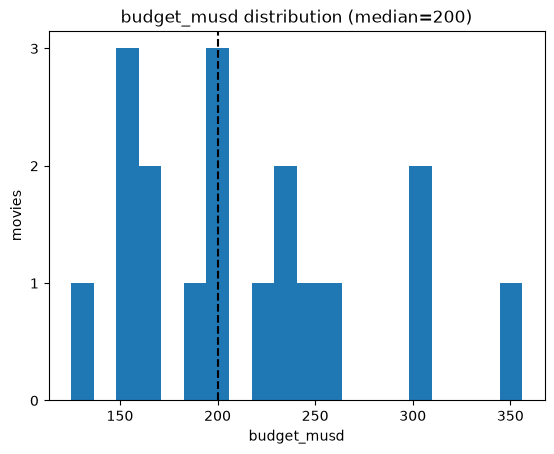

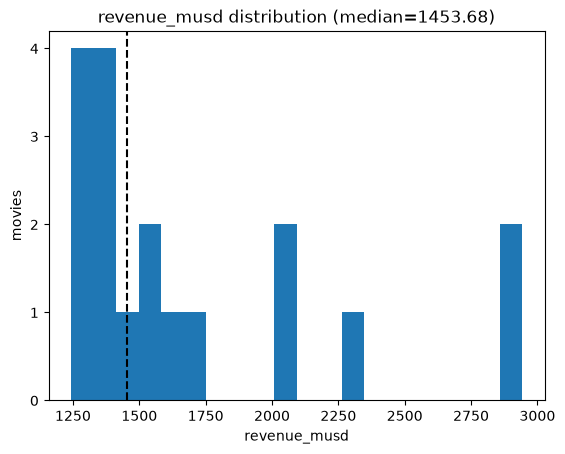

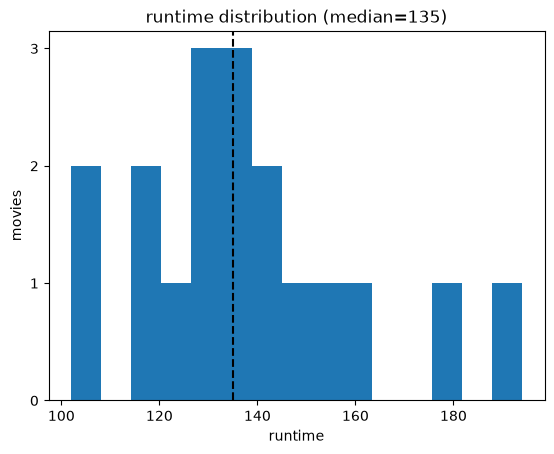

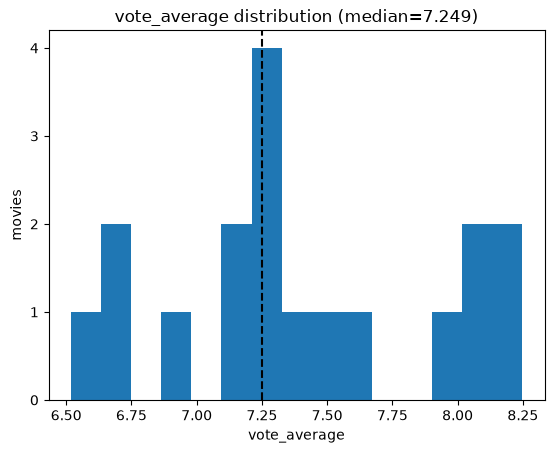

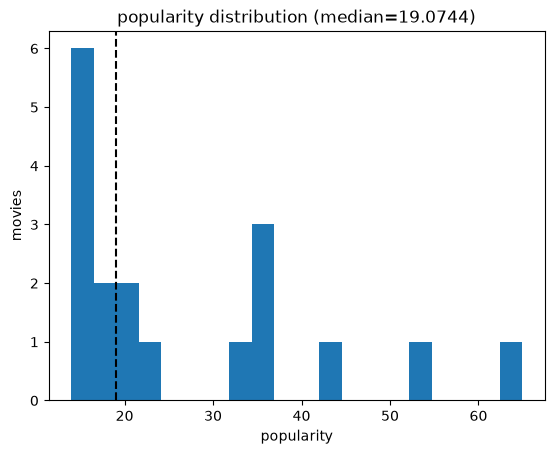

In [7]:
from src.visualize import plot_distribution

plot_distribution(df_cleaned, "budget_musd")
plt.show()

plot_distribution(df_cleaned, "revenue_musd")
plt.show()

plot_distribution(df_cleaned, "runtime", bins=15)
plt.show()

plot_distribution(df_cleaned, "vote_average", bins=15)
plt.show()

plot_distribution(df_cleaned, "popularity")
plt.show()

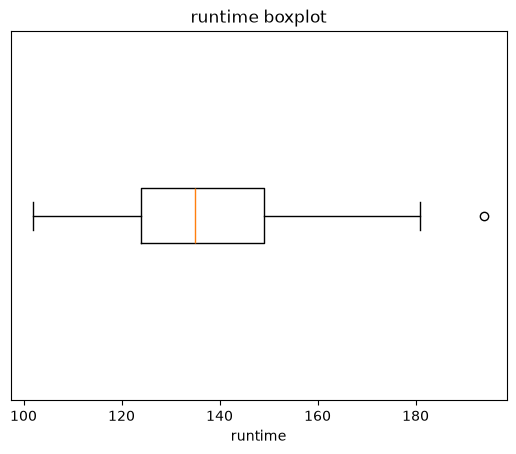

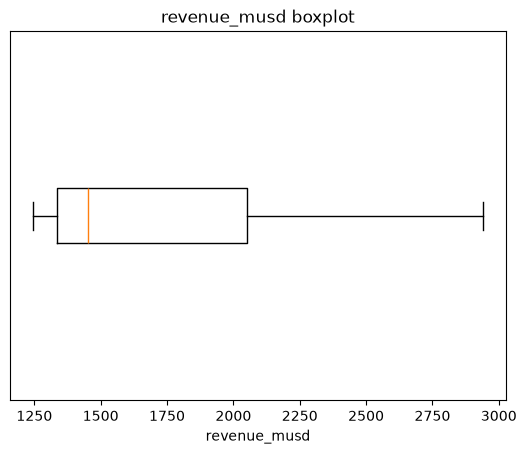

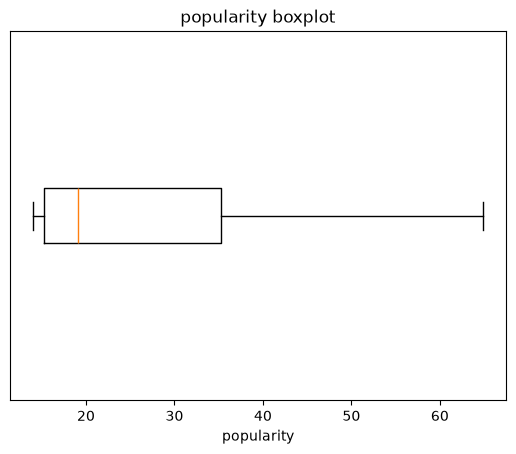

In [8]:
from src.visualize import plot_boxplot

plot_boxplot(df_cleaned, "runtime")
plt.show()

plot_boxplot(df_cleaned, "revenue_musd")
plt.show()

plot_boxplot(df_cleaned, "popularity")
plt.show()

what the distributions say on these 18 movies:

- budgets are tight: 125-356 musd, median 200, mean 214. the mean sits a bit
  above the median so the set leans expensive, but no outliers.
- revenue is right-skewed: median 1,454 vs mean 1,700. avatar (2,924) and
  endgame (2,942) are far above the 75% mark (2,052) but still inside the
  spark whisker (3,129). my pandas boxplot flagged both as outliers.
  the difference is the quartiles: percentile_approx picks a real value from
  the data, pandas interpolates between two. with 18 rows that moves the
  fence, so I read those two as "the top two", not as bad data.
- runtime sits at 102-194 min, median 135. only titanic (194) is past the fence.
- ratings barely move: 6.5-8.25, no outliers. expected, these are heavily
  voted blockbusters, not a random sample of all films.
- popularity is the most skewed: median 19.1, max 64.9 (endgame), right on
  the fence. popularity is a "right now" score, so older films sit low.
- every film has at least 10,557 votes, so the ">= 10 votes" rule for the
  rating lists drops nothing here.

## check the extracted columns

the brief asks for value_counts on the columns I built, to spot odd values
before I trust them. a cell like "Action|Adventure" counts once for each.

In [9]:
from src.cleaning import inspect_anomalies

EXTRACTED = ["belongs_to_collection", "genres", "spoken_languages",
             "production_countries", "production_companies", "original_language"]
counts = inspect_anomalies(df_cleaned, EXTRACTED)
for col, table in counts.items():
    table.show(truncate=False)

+-----------------------------------+-----+
|belongs_to_collection              |count|
+-----------------------------------+-----+
|The Avengers Collection            |4    |
|Frozen Collection                  |2    |
|Jurassic Park Collection           |2    |
|Star Wars Collection               |2    |
|Avatar Collection                  |1    |
|Black Panther Collection           |1    |
|Harry Potter Collection            |1    |
|The Fast and the Furious Collection|1    |
|The Incredibles Collection         |1    |
|The Lion King (Reboot) Collection  |1    |
+-----------------------------------+-----+

+---------------+-----+
|genres         |count|
+---------------+-----+
|Adventure      |15   |
|Action         |10   |
|Science Fiction|10   |
|Family         |5    |
|Animation      |4    |
|Fantasy        |4    |
|Thriller       |3    |
|Drama          |2    |
|Romance        |2    |
|Comedy         |1    |
+---------------+-----+

+----------------+-----+
|spoken_languages|cou

+------------------------+-----+
|production_countries    |count|
+------------------------+-----+
|United States of America|18   |
|United Kingdom          |2    |
+------------------------+-----+

+-----------------------------+-----+
|production_companies         |count|
+-----------------------------+-----+
|Marvel Studios               |5    |
|Universal Pictures           |3    |
|20th Century Fox             |2    |
|Amblin Entertainment         |2    |
|Lightstorm Entertainment     |2    |
|Lucasfilm Ltd.               |2    |
|Walt Disney Animation Studios|2    |
|Walt Disney Pictures         |2    |
|Bad Robot                    |1    |
|Dune Entertainment           |1    |
+-----------------------------+-----+

+-----------------+-----+
|original_language|count|
+-----------------+-----+
|en               |18   |
+-----------------+-----+



## profit and roi

In [10]:
from src.kpis import add_profit_roi, rank

df_enriched = add_profit_roi(df_cleaned).cache()
df_enriched.select("title", "profit_musd", "roi").show(5, truncate=False)

print("top revenue")
rank(df_enriched, "revenue_musd").show(truncate=False)
print("top profit")
rank(df_enriched, "profit_musd").show(truncate=False)
print("low profit")
rank(df_enriched, "profit_musd", ascending=True).show(truncate=False)

C:\Program Files\Python313\Lib\site-packages\pyspark\sql\udf.py:135: UserWarning: Cannot infer the eval type from type hints. 
  warnings.warn("Cannot infer the eval type from type hints. ", UserWarning)


+--------------------------------------------+-----------+-----------------+
|title                                       |profit_musd|roi              |
+--------------------------------------------+-----------+-----------------+
|Titanic                                     |2064.162353|11.320811765     |
|Harry Potter and the Deathly Hallows: Part 2|1216.511219|10.732089752     |
|Avatar                                      |2686.706026|12.33631234599156|
|The Avengers                                |1298.815515|6.903706886363636|
|Avengers: Age of Ultron                     |1170.403694|5.98044125106383 |
+--------------------------------------------+-----------+-----------------+
only showing top 5 rows
top revenue


+----------------------------+------------+
|title                       |revenue_musd|
+----------------------------+------------+
|Avengers: Endgame           |2942.186933 |
|Avatar                      |2923.706026 |
|Titanic                     |2264.162353 |
|Star Wars: The Force Awakens|2068.223624 |
|Avengers: Infinity War      |2052.415039 |
+----------------------------+------------+

top profit
+----------------------------+------------------+
|title                       |profit_musd       |
+----------------------------+------------------+
|Avatar                      |2686.706026       |
|Avengers: Endgame           |2586.186933       |
|Titanic                     |2064.162353       |
|Star Wars: The Force Awakens|1823.2236240000002|
|Avengers: Infinity War      |1752.415039       |
+----------------------------+------------------+

low profit


+------------------------------+-----------+
|title                         |profit_musd|
+------------------------------+-----------+
|Star Wars: The Last Jedi      |1034.407706|
|Incredibles 2                 |1043.225667|
|Beauty and the Beast          |1106.115964|
|Frozen                        |1124.219009|
|Jurassic World: Fallen Kingdom|1140.469037|
+------------------------------+-----------+



## more rankings

`rankings` gives all ten lists. roi only counts films with budget >= 10M and
ratings only films with >= 10 votes, like the brief says.

In [11]:
from src.kpis import rankings

for name, table in rankings(df_enriched).items():
    print(name)
    table.show(truncate=False)

top revenue
+----------------------------+------------+
|title                       |revenue_musd|
+----------------------------+------------+
|Avengers: Endgame           |2942.186933 |
|Avatar                      |2923.706026 |
|Titanic                     |2264.162353 |
|Star Wars: The Force Awakens|2068.223624 |
|Avengers: Infinity War      |2052.415039 |
+----------------------------+------------+

top budget
+----------------------------+-----------+
|title                       |budget_musd|
+----------------------------+-----------+
|Avengers: Endgame           |356.0      |
|Avengers: Infinity War      |300.0      |
|Star Wars: The Last Jedi    |300.0      |
|The Lion King               |260.0      |
|Star Wars: The Force Awakens|245.0      |
+----------------------------+-----------+

top profit


+----------------------------+------------------+
|title                       |profit_musd       |
+----------------------------+------------------+
|Avatar                      |2686.706026       |
|Avengers: Endgame           |2586.186933       |
|Titanic                     |2064.162353       |
|Star Wars: The Force Awakens|1823.2236240000002|
|Avengers: Infinity War      |1752.415039       |
+----------------------------+------------------+

low profit
+------------------------------+-----------+
|title                         |profit_musd|
+------------------------------+-----------+
|Star Wars: The Last Jedi      |1034.407706|
|Incredibles 2                 |1043.225667|
|Beauty and the Beast          |1106.115964|
|Frozen                        |1124.219009|
|Jurassic World: Fallen Kingdom|1140.469037|
+------------------------------+-----------+

top roi (budget >= 10M)


+--------------------------------------------+-----------------+
|title                                       |roi              |
+--------------------------------------------+-----------------+
|Avatar                                      |12.33631234599156|
|Titanic                                     |11.320811765     |
|Jurassic World                              |11.14358296      |
|Harry Potter and the Deathly Hallows: Part 2|10.732089752     |
|Frozen II                                   |9.691223173333332|
+--------------------------------------------+-----------------+

low roi (budget >= 10M)
+------------------------+------------------+
|title                   |roi               |
+------------------------+------------------+
|Star Wars: The Last Jedi|4.448025686666667 |
|Avengers: Age of Ultron |5.98044125106383  |
|Incredibles 2           |6.216128335       |
|The Lion King           |6.3923877653846155|
|Black Panther           |6.749630415       |
+---------------------

+----------------------+----------+
|title                 |vote_count|
+----------------------+----------+
|The Avengers          |40259     |
|Avatar                |34959     |
|Avengers: Infinity War|33324     |
|Avengers: Endgame     |29209     |
|Titanic               |28009     |
+----------------------+----------+

top rated (>= 10 votes)
+--------------------------------------------+------------+
|title                                       |vote_average|
+--------------------------------------------+------------+
|Avengers: Endgame                           |8.247       |
|Avengers: Infinity War                      |8.246       |
|The Avengers                                |8.083       |
|Harry Potter and the Deathly Hallows: Part 2|8.082       |
|Titanic                                     |7.902       |
+--------------------------------------------+------------+

low rated (>= 10 votes)


+------------------------------+------------+
|title                         |vote_average|
+------------------------------+------------+
|Jurassic World: Fallen Kingdom|6.519       |
|Jurassic World                |6.7         |
|Star Wars: The Last Jedi      |6.73        |
|Beauty and the Beast          |6.973       |
|The Lion King                 |7.1         |
+------------------------------+------------+

most popular
+-----------------------+----------+
|title                  |popularity|
+-----------------------+----------+
|Avengers: Endgame      |64.9252   |
|Avengers: Infinity War |54.4601   |
|The Avengers           |42.3771   |
|Avengers: Age of Ultron|35.9699   |
|Titanic                |35.2201   |
+-----------------------+----------+



## udf vs built in

the brief asks for a udf for the ranking. `rank` is my reusable ranking
function, but it is plain spark column code, not a spark udf, on purpose.
below is a real python udf for roi next to the built in division. same answer,
but the plan shows `ArrowEvalPython`: every row goes from the jvm to a python
worker and back, and spark can not look inside it to optimise.

In [12]:
from src.kpis import roi_udf

both = df_enriched.select("title", "roi", roi_udf("revenue_musd", "budget_musd").alias("roi_from_udf"))
both.show(5, truncate=False)
print("rows where they differ:", both.filter(~F.col("roi").eqNullSafe(F.col("roi_from_udf"))).count())
both.explain()

+--------------------------------------------+-----------------+-----------------+
|title                                       |roi              |roi_from_udf     |
+--------------------------------------------+-----------------+-----------------+
|Titanic                                     |11.320811765     |11.320811765     |
|Harry Potter and the Deathly Hallows: Part 2|10.732089752     |10.732089752     |
|Avatar                                      |12.33631234599156|12.33631234599156|
|The Avengers                                |6.903706886363636|6.903706886363636|
|Avengers: Age of Ultron                     |5.98044125106383 |5.98044125106383 |
+--------------------------------------------+-----------------+-----------------+
only showing top 5 rows


rows where they differ: 0
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [title#1, roi#20688, pythonUDF0#29771 AS roi_from_udf#28376]
   +- ArrowEvalPython [roi_udf(revenue_musd#2117, budget_musd#2116)#28375], [pythonUDF0#29771], 101
      +- InMemoryTableScan [title#1, budget_musd#2116, revenue_musd#2117, roi#20688]
            +- InMemoryRelation [idx#2121, id#2105L, title#1, tagline#2120, release_date#2112, genres#2081, belongs_to_collection#2079, original_language#10, budget_musd#2116, revenue_musd#2117, production_companies#2090, production_countries#2087, vote_count#2109L, vote_average#2118, popularity#2108, runtime#2115, overview#2119, spoken_languages#2084, poster_path#12, cast#2093, cast_size#2096, director#2098, crew_size#2103, profit_musd#20687, roi#20688], StorageLevel(disk, memory, deserialized, 1 replicas)
                  +- AdaptiveSparkPlan isFinalPlan=true
                     +- == Final Plan ==
                        ResultQueryStage 1
        

## searches

In [13]:
from src.kpis import search_willis_scifi_action, search_thurman_tarantino

w = search_willis_scifi_action(df_enriched)
print("willis found:", w.count())
w.show(truncate=False)

t = search_thurman_tarantino(df_enriched)
print("thurman found:", t.count())
t.show(truncate=False)

willis found: 0


+-----+------+------------+
|title|genres|vote_average|
+-----+------+------------+
+-----+------+------------+



thurman found: 0


+-----+--------+-------+
|title|director|runtime|
+-----+--------+-------+
+-----+--------+-------+



0 for both. the 18 ids are big franchise films, none has bruce willis or a
tarantino film in it. the searches are tested on fake rows in
`tests/test_kpis.py`, so 0 here is the data, not a bug.

## franchise and directors

In [14]:
from src.kpis import franchise_vs_standalone, top_franchises, top_directors

franchise_vs_standalone(df_enriched).show(truncate=False)
top_franchises(df_enriched).show(truncate=False)
top_directors(df_enriched).show(truncate=False)

+----------+------+------------+----------+-----------+---------------+-----------+
|group     |movies|mean_revenue|median_roi|mean_budget|mean_popularity|mean_rating|
+----------+------+------------+----------+-----------+---------------+-----------+
|franchise |16    |1691.7      |7.71      |218.0      |27.06          |7.4        |
|standalone|2     |1765.1      |7.91      |180.0      |26.53          |7.44       |
+----------+------+------------+----------+-----------+---------------+-----------+



+-----------------------------------+------+-------------+------------+------------+-----------+-----------+
|franchise                          |movies|total_revenue|mean_revenue|total_budget|mean_budget|mean_rating|
+-----------------------------------+------+-------------+------------+------------+-----------+-----------+
|The Avengers Collection            |4     |7918.8       |1979.7      |1111.0      |277.8      |7.96       |
|Star Wars Collection               |2     |3402.6       |1701.3      |545.0       |272.5      |6.98       |
|Jurassic Park Collection           |2     |2982.0       |1491.0      |320.0       |160.0      |6.61       |
|Avatar Collection                  |1     |2923.7       |2923.7      |237.0       |237.0      |7.61       |
|Frozen Collection                  |2     |2727.9       |1364.0      |300.0       |150.0      |7.23       |
|The Lion King (Reboot) Collection  |1     |1662.0       |1662.0      |260.0       |260.0      |7.1        |
|The Fast and the F

+---------------+------+-------------+-----------+
|director       |movies|total_revenue|mean_rating|
+---------------+------+-------------+-----------+
|James Cameron  |2     |5187.9       |7.76       |
|Anthony Russo  |2     |4994.6       |8.25       |
|Joe Russo      |2     |4994.6       |8.25       |
|Joss Whedon    |2     |2924.2       |7.68       |
|Chris Buck     |2     |2727.9       |7.23       |
|Jennifer Lee   |2     |2727.9       |7.23       |
|J.J. Abrams    |1     |2068.2       |7.24       |
|Colin Trevorrow|1     |1671.5       |6.7        |
|Jon Favreau    |1     |1662.0       |7.1        |
|James Wan      |1     |1515.4       |7.21       |
+---------------+------+-------------+-----------+



## charts

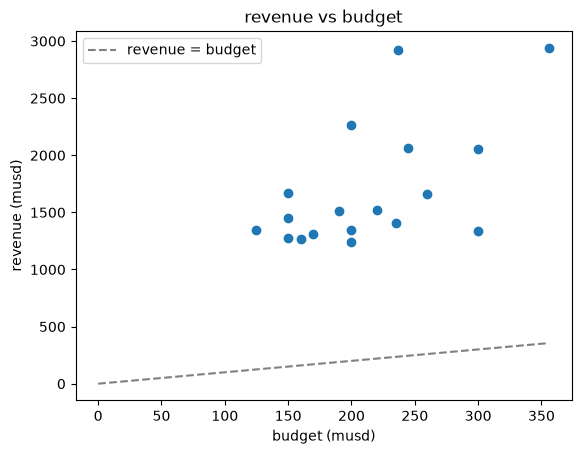

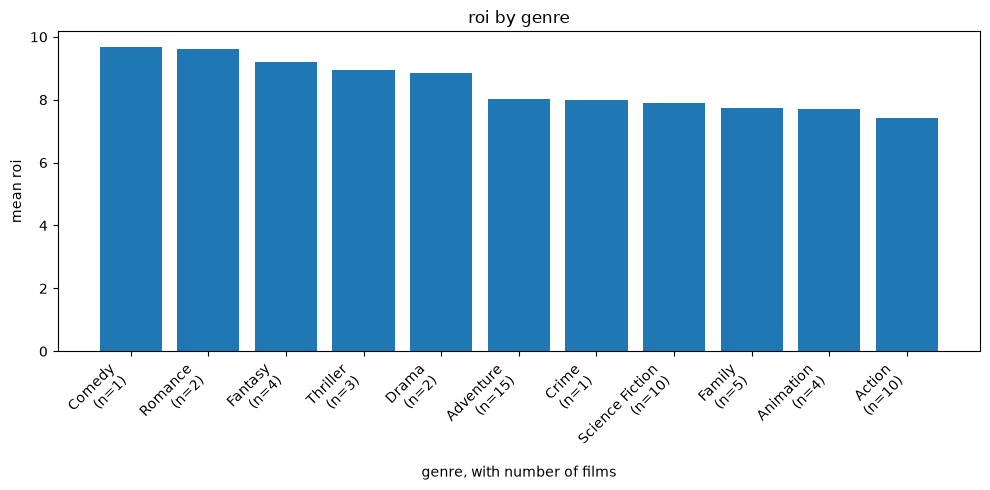

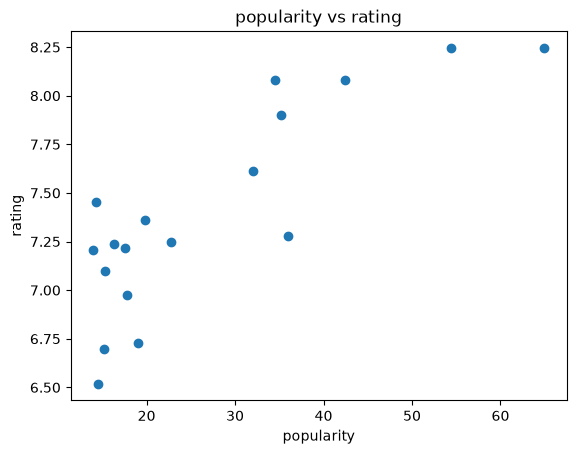

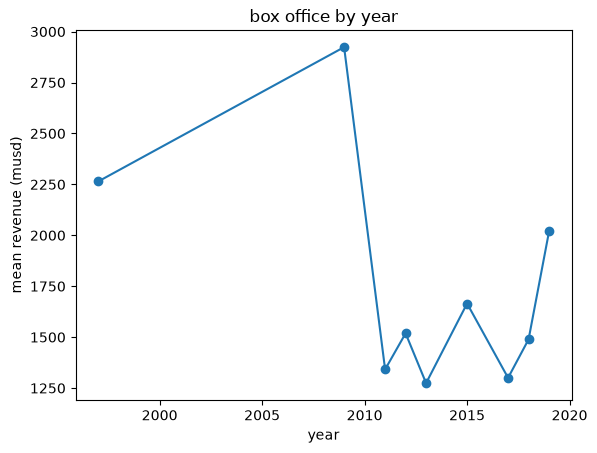

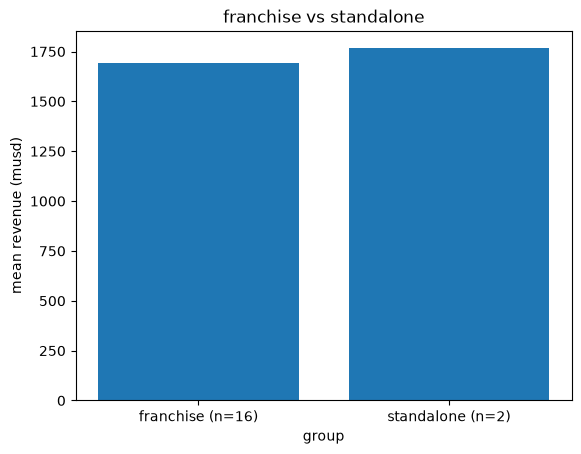

In [15]:
from src.visualize import (plot_revenue_vs_budget, plot_roi_by_genre, plot_popularity_vs_rating,
                           plot_yearly_box_office, plot_franchise_vs_standalone)

plot_revenue_vs_budget(df_enriched)
plt.show()

plot_roi_by_genre(df_enriched)
plt.show()

plot_popularity_vs_rating(df_enriched)
plt.show()

plot_yearly_box_office(df_enriched)
plt.show()

plot_franchise_vs_standalone(df_enriched)
plt.show()

## save and stop

parquet keeps the types and is columnar. `coalesce(1)` because 18 rows do not
need 4 files, `overwrite` so a rerun gives the same output. then free the cache
and stop spark so the jvm lets go of memory.

In [16]:
CLEAN_PATH = "data/movies_clean.parquet"

df_enriched.coalesce(1).write.mode("overwrite").parquet(CLEAN_PATH)
print("rows read back:", spark.read.parquet(CLEAN_PATH).count())

df_enriched.unpersist()
df_cleaned.unpersist()
df_raw.unpersist()
spark.stop()

rows read back: 18
